<a href="https://colab.research.google.com/github/ncbx666/architecture-classification/blob/main/architectural_style_recognition_intro_to_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ncbx666","key":"REMOVED_KAGGLE_KEY"}'}

In [ ]:
!mv /content/kaggle.json /root/.config/kaggle/

In [ ]:
import kaggle
from fastai.vision.all import *
from torchvision.models import inception_v3, vgg16_bn

## Download dataset from Kaggle

In [ ]:
# Скачивание датасета
kaggle.api.dataset_download_files("dumitrux/architectural-styles-dataset", path=".", unzip=True)

Dataset URL: https://www.kaggle.com/datasets/dumitrux/architectural-styles-dataset


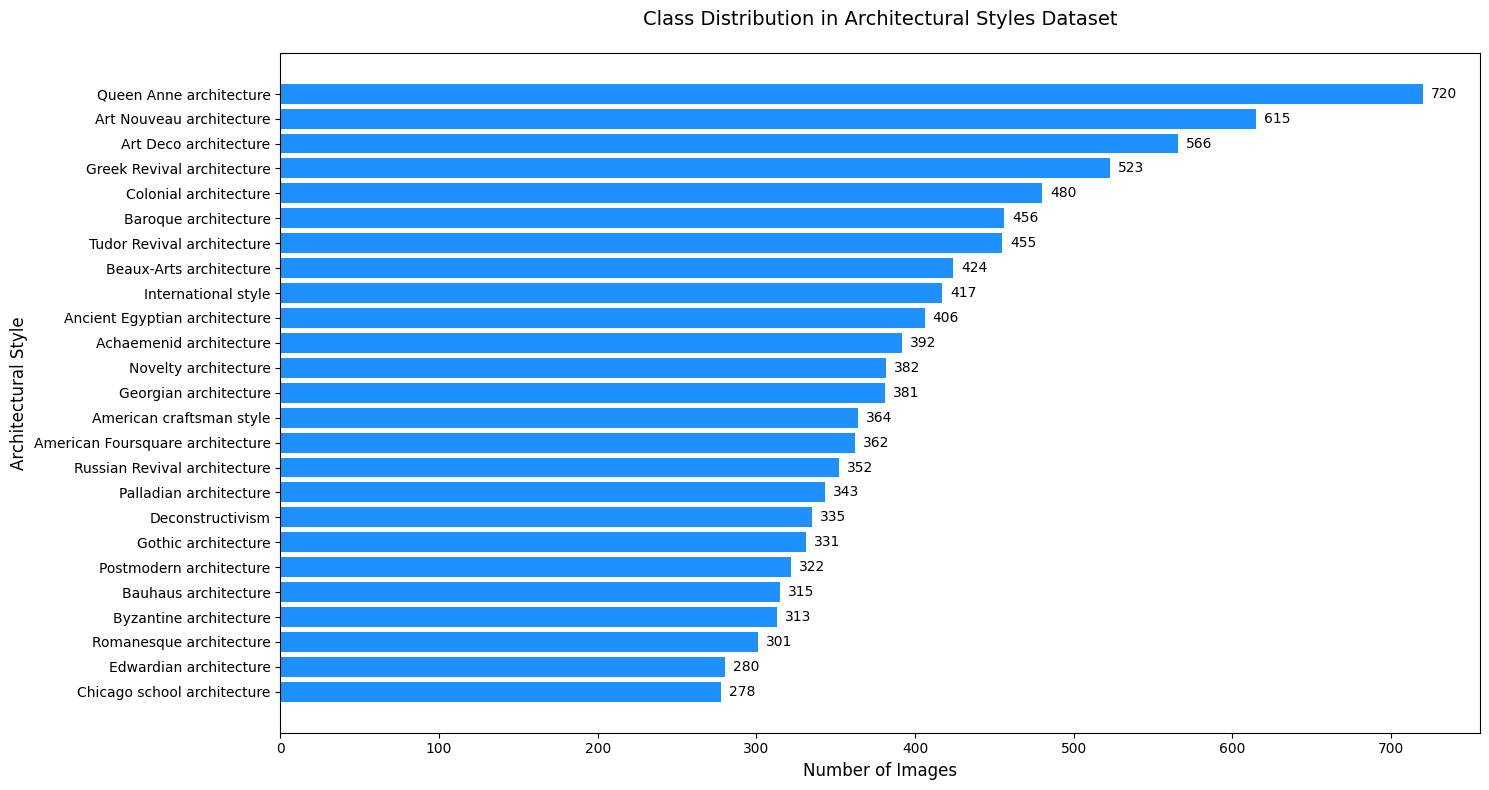


Подробная статистика:
             Architectural Style  Number of Images
         Queen Anne architecture               720
        Art Nouveau architecture               615
           Art Deco architecture               566
      Greek Revival architecture               523
           Colonial architecture               480
            Baroque architecture               456
      Tudor Revival architecture               455
         Beaux-Arts architecture               424
             International style               417
   Ancient Egyptian architecture               406
         Achaemenid architecture               392
            Novelty architecture               382
           Georgian architecture               381
        American craftsman style               364
American Foursquare architecture               362
    Russian Revival architecture               352
          Palladian architecture               343
                Deconstructivism               335
        

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Путь к датасету
path = Path("architectural-styles-dataset")

# Собираем статистику по классам
class_counts = {}
for style_dir in path.iterdir():
    if style_dir.is_dir():
        num_images = len(list(style_dir.glob("*.*")))  # Считаем все файлы
        class_counts[style_dir.name] = num_images

# Создаем DataFrame
df = pd.DataFrame({
    "Architectural Style": class_counts.keys(),
    "Number of Images": class_counts.values()
}).sort_values("Number of Images", ascending=False)

# Визуализация
plt.figure(figsize=(15, 8))
bars = plt.barh(df["Architectural Style"], df["Number of Images"], color="dodgerblue")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Architectural Style", fontsize=12)
plt.title("Class Distribution in Architectural Styles Dataset", fontsize=14, pad=20)
plt.gca().invert_yaxis()  # Самый частый класс сверху

# Добавляем аннотации с количеством
for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f"{int(width)}",
             ha="left", va="center")

plt.tight_layout()
plt.show()

# Выводим таблицу
print("\nПодробная статистика:")
print(df.to_string(index=False))

✅ Датасет сбалансирован.


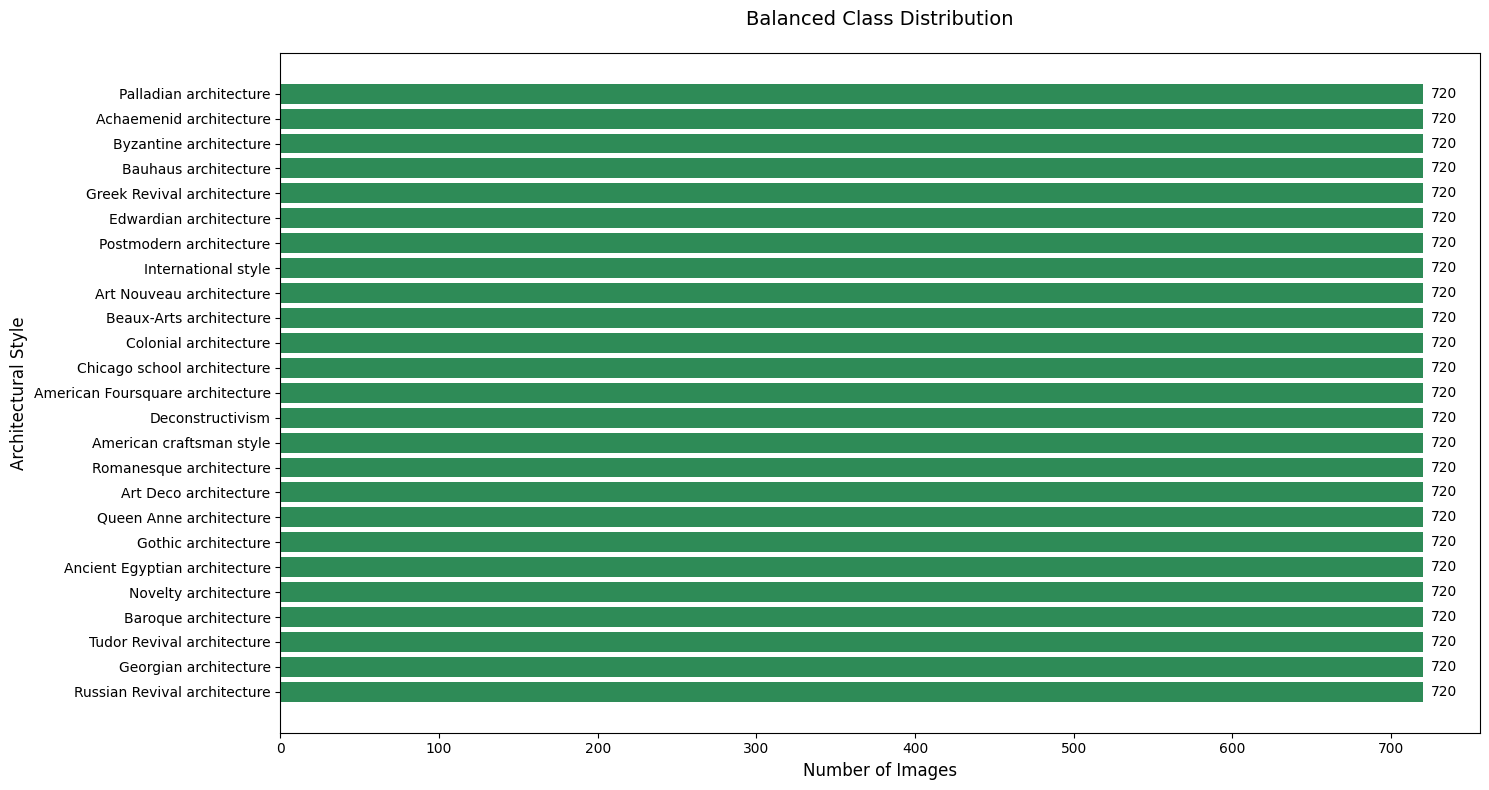

In [ ]:
from fastai.vision.all import *
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from torchvision.transforms import functional as TF

# Пути
path_original = Path("architectural-styles-dataset")
path_balanced = Path("balanced-architectural-styles-dataset")
path_balanced.mkdir(exist_ok=True)

# Статистика
class_counts = {p.name: len(list(p.glob("*.*"))) for p in path_original.iterdir() if p.is_dir()}
max_count = max(class_counts.values())

# Аугментации
aug_tfms = aug_transforms(
    do_flip=True, flip_vert=False, max_rotate=10, max_zoom=1.1,
    max_lighting=0.2, max_warp=0.2, p_affine=0.75, p_lighting=0.75
)
pipeline = Pipeline([Resize(256), *aug_tfms])

# Балансировка
for class_name, count in class_counts.items():
    orig_dir = path_original/class_name
    new_dir = path_balanced/class_name
    new_dir.mkdir(parents=True, exist_ok=True)

    files = list(orig_dir.glob("*.*"))

    # Копируем оригиналы
    for file in files:
        shutil.copy(file, new_dir/file.name)

    idx = 0
    while count < max_count:
        img_path = files[idx % len(files)]
        img = PILImage.create(img_path)

        # Приводим к FloatTensor [0,1] и добавляем батч
        tensor_img = ToTensor()(img).float().unsqueeze(0) / 255.0  # (1, C, H, W)

        # Применяем аугментации
        aug_img = pipeline(tensor_img)[0]  # Снимаем батч

        # Обратно в PIL
        aug_pil = TF.to_pil_image(torch.clamp(aug_img * 255, 0, 255).byte())

        new_name = f"{img_path.stem}_aug_{count}.jpg"
        aug_pil.save(new_dir/new_name)
        count += 1
        idx += 1

print("✅ Датасет сбалансирован.")

# Статистика
class_counts_bal = {p.name: len(list(p.glob("*.*"))) for p in path_balanced.iterdir() if p.is_dir()}
df_bal = pd.DataFrame({
    "Architectural Style": class_counts_bal.keys(),
    "Number of Images": class_counts_bal.values()
}).sort_values("Number of Images", ascending=False)

# Визуализация
plt.figure(figsize=(15, 8))
bars = plt.barh(df_bal["Architectural Style"], df_bal["Number of Images"], color="seagreen")
plt.xlabel("Number of Images", fontsize=12)
plt.ylabel("Architectural Style", fontsize=12)
plt.title("Balanced Class Distribution", fontsize=14, pad=20)
plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f"{int(width)}",
             ha="left", va="center")

plt.tight_layout()
plt.show()

In [ ]:
dls = ImageDataLoaders.from_folder(
    path="balanced-architectural-styles-dataset",
    valid_pct=0.2,
    item_tfms=Resize(299),
    bs=16
)

print("✅ DataLoaders созданы.")


✅ DataLoaders созданы.


# Resnet50

## Training: resnet50

### Training

In [ ]:
learn_resnet = vision_learner(
    dls,
    resnet50,
    metrics=accuracy,
    wd=1e-1
)
learn_resnet.freeze()

SuggestedLRs(valley=0.001737800776027143)

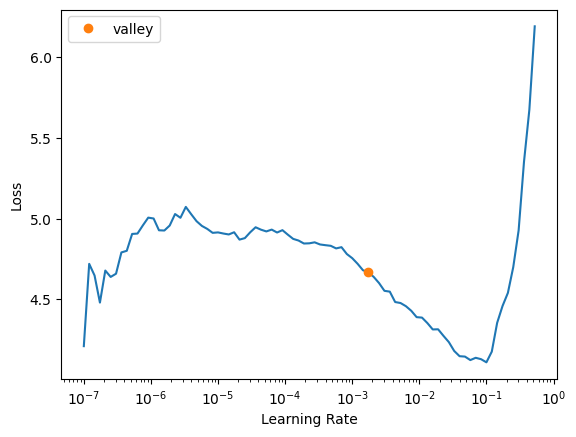

In [ ]:
learn_resnet.lr_find()

Начинаем обучение...


epoch,train_loss,valid_loss,accuracy,time
0,1.829929,1.379282,0.597500,04:03
1,1.347442,0.990010,0.706944,04:04
2,1.106360,0.816204,0.746667,04:02
3,0.917942,0.775768,0.779444,04:00
4,0.714966,0.659043,0.801944,04:01
5,0.586724,0.704071,0.816389,04:01
6,0.540728,0.604857,0.823611,04:04


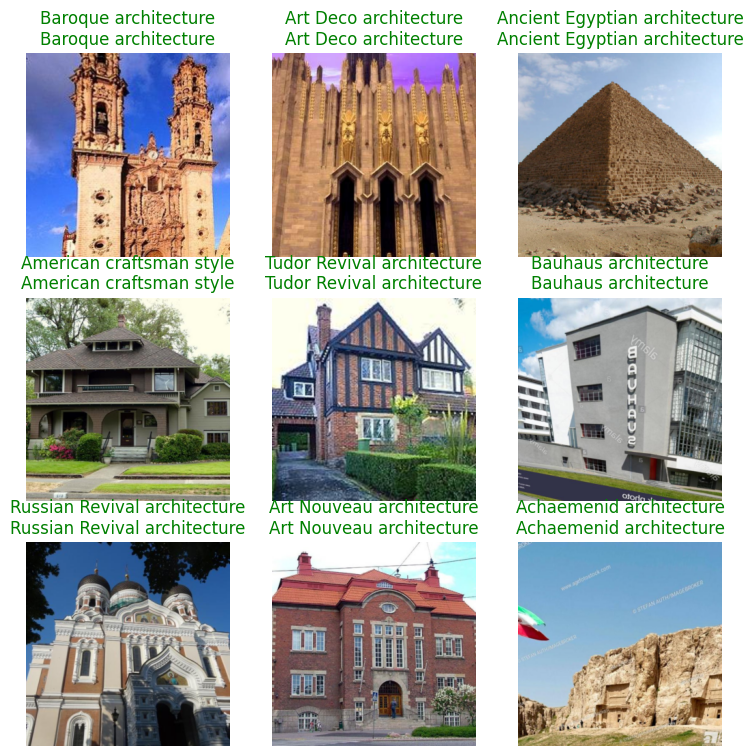

In [ ]:
# 5. Обучение (с прогрессом)
print("Начинаем обучение...")
learn_resnet.fit_one_cycle(7, lr_max=1e-3)

In [ ]:
learn_resnet.save('stage-1-resnet50-6cycles')

Path('balanced-architectural-styles-dataset/models/stage-1-resnet50-6cycles.pth')

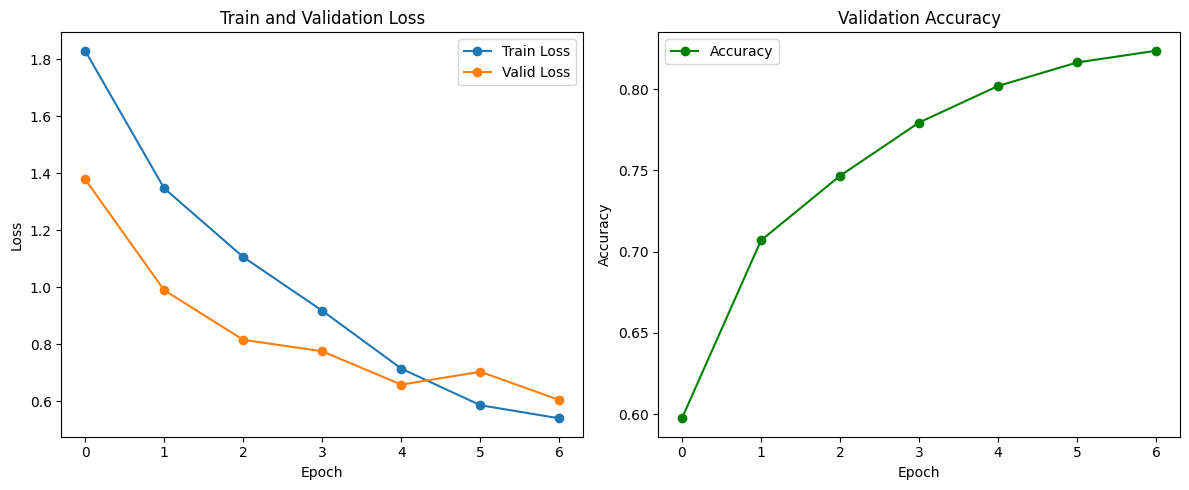

In [ ]:
import matplotlib.pyplot as plt

# Данные из таблицы
epochs = list(range(7))
train_loss = [1.829929, 1.347442, 1.106360, 0.917942, 0.714966, 0.586724, 0.540728]
valid_loss = [1.379282, 0.990010, 0.816207, 0.775768, 0.659043, 0.704071, 0.604857]
accuracy = [0.597500, 0.706944, 0.746667, 0.779444, 0.801944, 0.816389, 0.823611]

plt.figure(figsize=(12,5))

# График loss
plt.subplot(1,2,1)
plt.plot(epochs, train_loss, label='Train Loss', marker='o')
plt.plot(epochs, valid_loss, label='Valid Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()

# График accuracy
plt.subplot(1,2,2)
plt.plot(epochs, accuracy, label='Accuracy', color='green', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


### Unfreezing, fine-tuning and learning rates

Поиск оптимального learning rate...


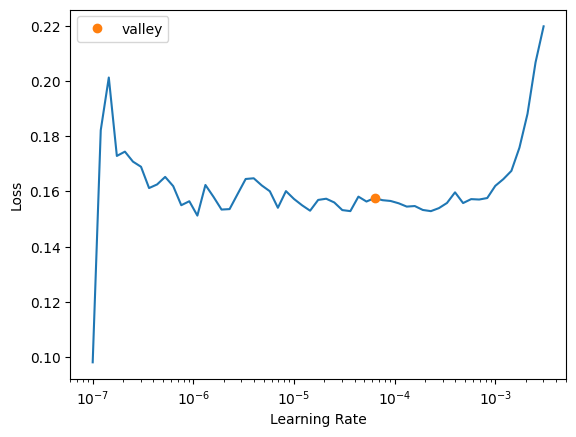

In [ ]:
# 1. Размораживаем все слои модели
learn_resnet.unfreeze()

# 2. Подбираем оптимальные learning rates
print("Поиск оптимального learning rate...")
lr_find_result = learn_resnet.lr_find()
plt.show()


Начинаем дообучение модели...


epoch,train_loss,valid_loss,accuracy,time
0,0.169542,0.408818,0.887222,02:58
1,0.170776,0.415530,0.886667,02:57
2,0.155012,0.410776,0.886389,02:56
3,0.144570,0.396552,0.891111,02:56
4,0.151087,0.397227,0.888611,02:57
5,0.141189,0.387787,0.891667,02:57
6,0.136558,0.398155,0.891667,02:56
7,0.146463,0.388720,0.893611,02:58
8,0.135307,0.392783,0.891667,02:56
9,0.140942,0.398461,0.889167,03:00


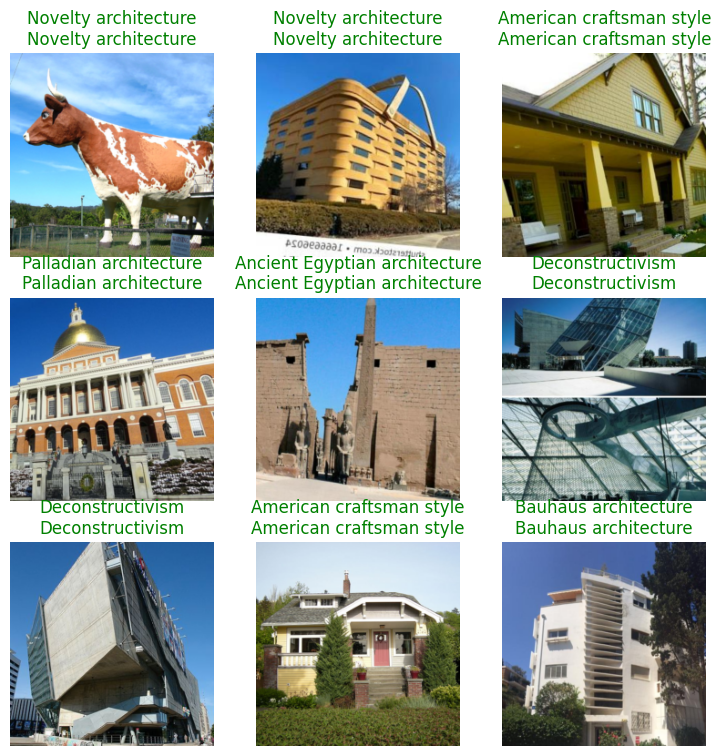

In [ ]:
# 4. Дообучение с выбранными learning rates
print("\nНачинаем дообучение модели...")
learn_resnet.fit_one_cycle(
    10,  # количество эпох
    lr_max=0.3*1e-5,  # диапазон learning rates
    wd=1e-1,  # weight decay
)

# 5. Показываем результаты
learn_resnet.show_results()

In [ ]:
learn_resnet.save('stage-2-resnet50', return_path=True)

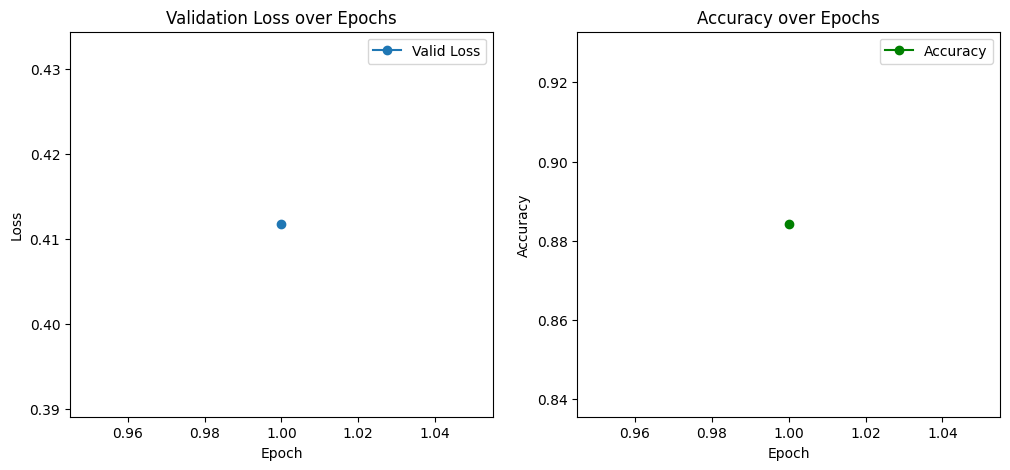

In [ ]:
# Теперь рисуем графики лосса и accuracy как для обучающей, так и валидационной части
import matplotlib.pyplot as plt

def plot_training_curve(recorder):
    # recorder.values: список эпох, где каждый элемент — [train_loss, valid_loss, accuracy]
    values = recorder.values
    train_loss = [v[0] for v in values]
    valid_loss = [v[1] for v in values]
    accuracy = [v[2] for v in values]

    epochs = range(1, len(train_loss)+1)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(epochs, train_loss, label='Train Loss')
    plt.plot(epochs, valid_loss, label='Valid Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train & Validation Loss')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, accuracy, label='Accuracy', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Validation Accuracy')
    plt.legend()

    plt.show()

# Построим графики
plot_training_curve(learn_resnet.recorder)

In [ ]:
interp = ClassificationInterpretation.from_learner(learn_resnet)

In [ ]:
interp.most_confused(min_val=3)

[('International style', 'Postmodern architecture', 7),
 ('International style', 'Art Deco architecture', 4),
 ('Tudor Revival architecture', 'American craftsman style', 4),
 ('American Foursquare architecture', 'American craftsman style', 3),
 ('Baroque architecture', 'Romanesque architecture', 3)]

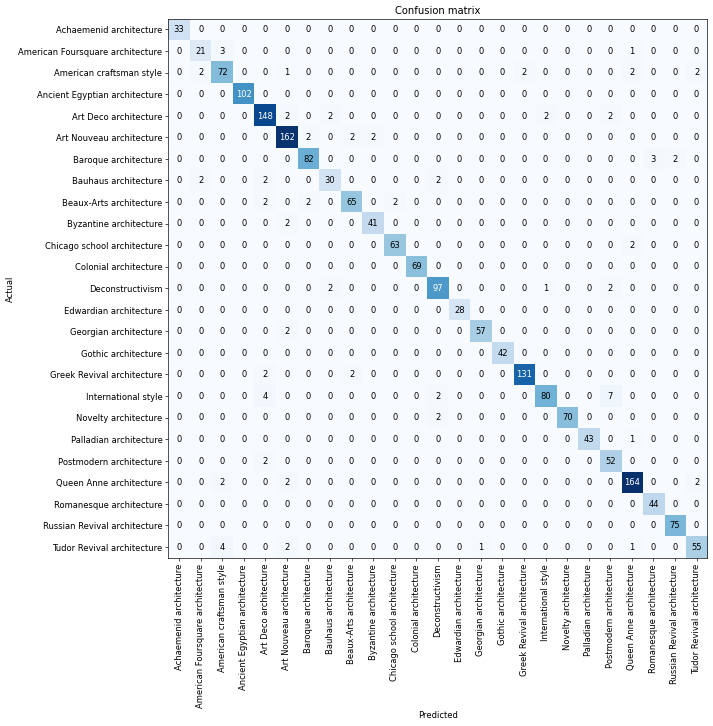

In [ ]:
interp.plot_confusion_matrix(figsize=(12,12), dpi=60)

Duplicate images on top losses, because of data augmentation

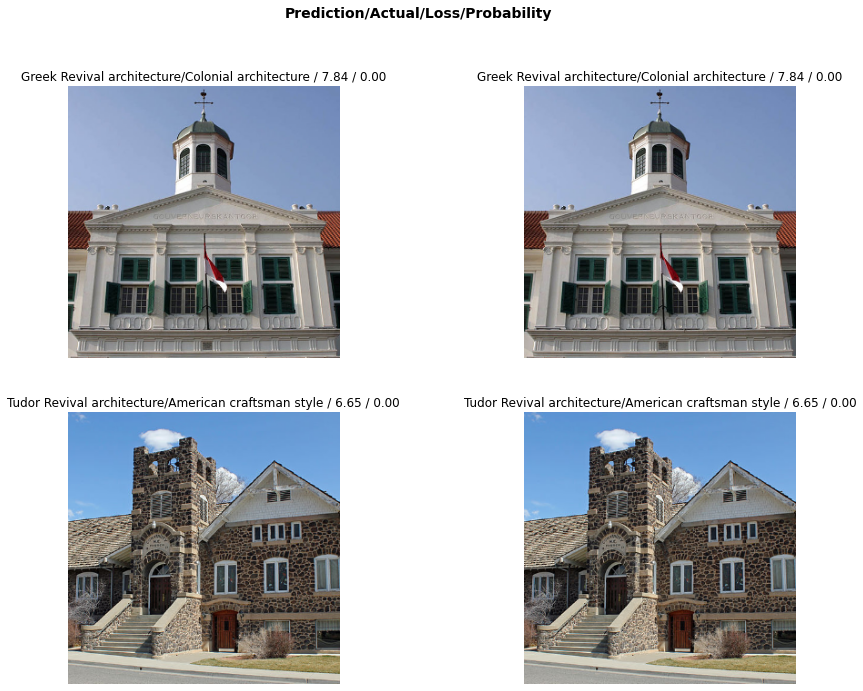

In [ ]:
interp.plot_top_losses(4, figsize=(15,11))

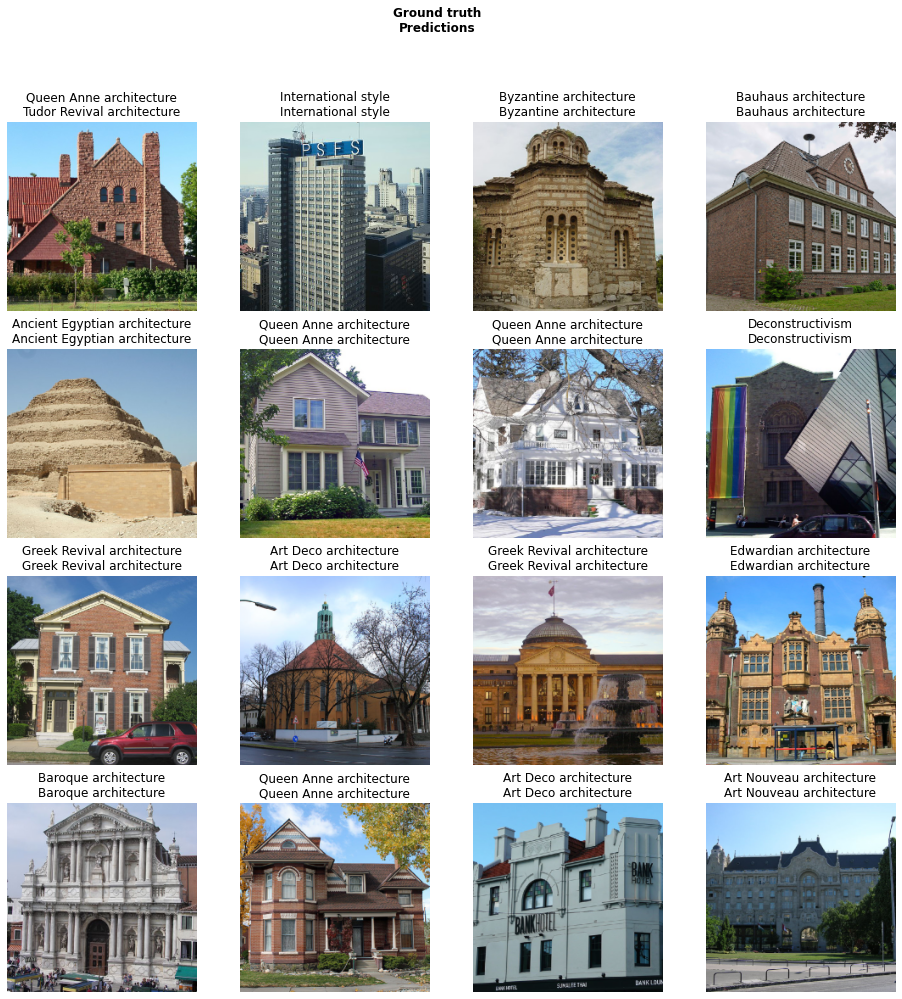

In [ ]:
learn.show_results(rows=4)

In [ ]:
img = open_image(path/'arcDataset'/'Bauhaus architecture'/'46_800px-Friedrichshafen_Hafenbahnhof_Zeppelinmuseum.jpg')
# img

In [ ]:
pred_class,pred_idx,outputs = learn.predict(img)
data.classes[int(pred_class)]

'Art Deco architecture'

In [ ]:
outputs

tensor([4.8131e-05, 4.0115e-04, 1.5859e-04, 1.8332e-05, 9.1667e-01, 2.8412e-04,
        6.4029e-06, 1.6311e-02, 1.4279e-04, 2.3726e-05, 3.7191e-04, 4.3844e-05,
        2.8516e-03, 1.0721e-04, 1.3770e-05, 5.1941e-05, 4.0738e-05, 6.0796e-02,
        2.3134e-04, 1.5984e-06, 1.3584e-03, 1.8242e-06, 2.2416e-05, 4.1732e-05,
        5.2506e-06])

# MobileNetV2


In [ ]:
from fastai.vision.all import *
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import torch.nn as nn

# Загружаем предобученную модель MobileNetV2 с весами
weights = MobileNet_V2_Weights.DEFAULT
model = mobilenet_v2(weights=weights)

# Заменяем последний слой на нужное число классов
num_classes = dls.c
model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

In [ ]:
# Инициализация слоя:
nn.init.kaiming_normal_(model.classifier[1].weight)
if model.classifier[1].bias is not None:
    nn.init.zeros_(model.classifier[1].bias)

# Создаем Learner
learn = Learner(
    dls,
    model,
    loss_func=CrossEntropyLossFlat(),
    metrics=accuracy,
    wd=1e-3
)

# Рекомендуется сначала заморозить базовую часть и обучать только голову,
# чтобы сохранить предобученные признаки:
learn.freeze()

In [ ]:
learn.fit_one_cycle(7, lr_max=0.001)

epoch,train_loss,valid_loss,accuracy,time
0,1.227458,1.185184,0.646389,03:17
1,1.220281,1.026519,0.690556,03:11
2,0.979624,0.965330,0.715833,03:08
3,0.695436,0.776930,0.755278,03:08
4,0.377619,0.586430,0.831389,03:12
5,0.183145,0.467566,0.869444,03:16
6,0.105975,0.454991,0.877222,03:13


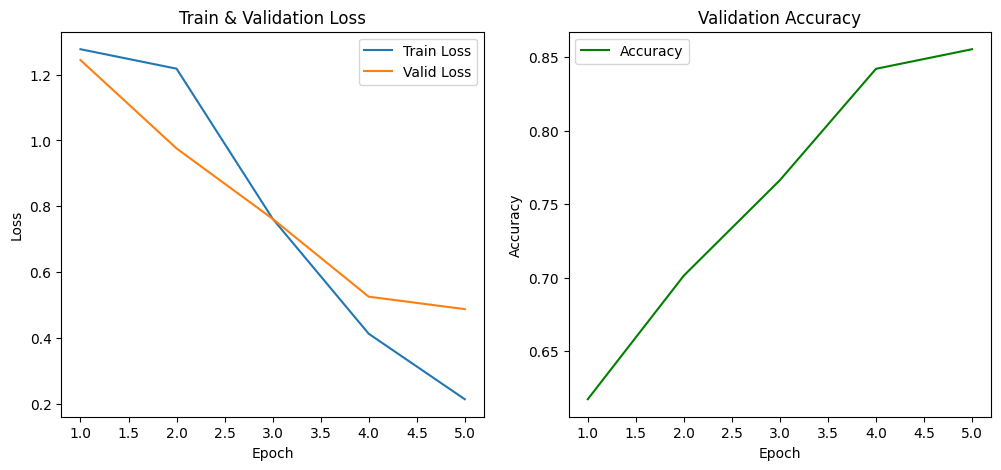

In [ ]:
# Теперь рисуем графики лосса и accuracy как для обучающей, так и валидационной части
import matplotlib.pyplot as plt

def plot_training_curve(recorder):
    # recorder.values: список эпох, где каждый элемент — [train_loss, valid_loss, accuracy]
    values = recorder.values
    train_loss = [v[0] for v in values]
    valid_loss = [v[1] for v in values]
    accuracy = [v[2] for v in values]

    epochs = range(1, len(train_loss)+1)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(epochs, train_loss, label='Train Loss')
    plt.plot(epochs, valid_loss, label='Valid Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train & Validation Loss')
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(epochs, accuracy, label='Accuracy', color='green')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.title('Validation Accuracy')
    plt.legend()

    plt.show()

# Построим графики
plot_training_curve(learn.recorder)

In [ ]:
import torch
torch.cuda.empty_cache()

# Если используешь PyTorch >= 1.9, дополнительно можно:
torch.cuda.reset_peak_memory_stats()


In [ ]:
import torch
import gc


torch.cuda.empty_cache()
gc.collect()


25365

In [ ]:
torch.cuda.empty_cache()


In [ ]:
import torch
import gc

# Удаляем все объекты, которые могут держать память
for obj in dir():
    if obj.startswith('learn') or obj.startswith('model') or obj.startswith('xb') or obj.startswith('yb'):
        del globals()[obj]

# Вызываем сборщик мусора для очистки неиспользуемой памяти в Python
gc.collect()

# Очищаем кэш CUDA
torch.cuda.empty_cache()


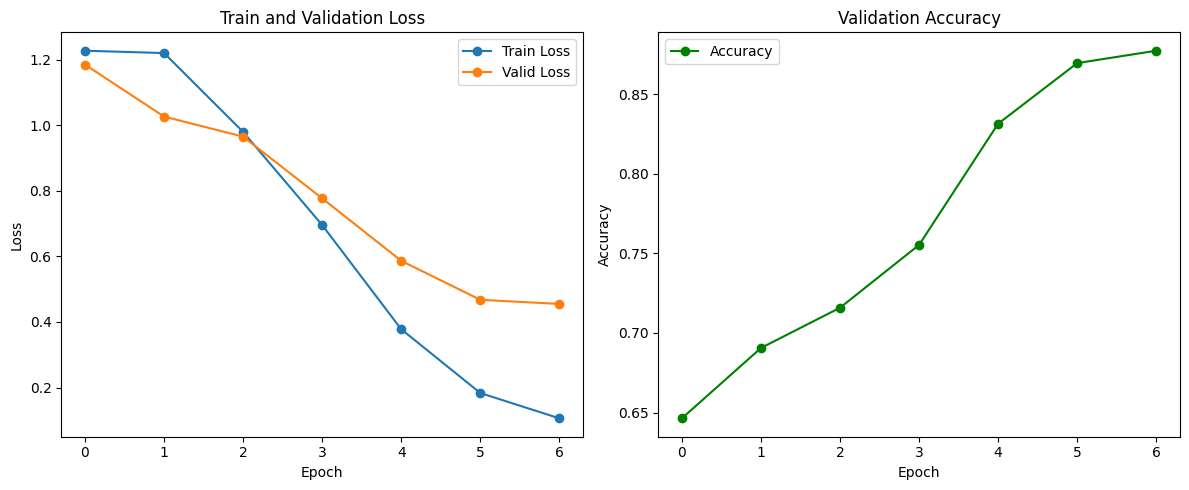

In [1]:
import matplotlib.pyplot as plt

# Данные из таблицы
epochs = list(range(7))
train_loss = [1.227458, 1.220281, 0.979624, 0.695436, 0.377619, 0.183145, 0.105975]
valid_loss = [1.185184, 1.026519, 0.965330, 0.776930, 0.586430, 0.467566, 0.454991]
accuracy = [0.646389, 0.690556, 0.715833, 0.755278, 0.831389, 0.869444, 0.877222]

plt.figure(figsize=(12,5))

# График loss
plt.subplot(1,2,1)
plt.plot(epochs, train_loss, label='Train Loss', marker='o')
plt.plot(epochs, valid_loss, label='Valid Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()

# График accuracy
plt.subplot(1,2,2)
plt.plot(epochs, accuracy, label='Accuracy', color='green', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.show()
